## Baseline: compatibilidad de outfits

Clasificación binaria de `compatible` con regresión logística y árbol de decisión.
Si el modelo elegido cumple los umbrales en test, se ajusta además el score continuo.

Umbrales de éxito: F1 ≥ 0.85, accuracy ≥ 0.82, AUC-ROC ≥ 0.88.

Quedan fuera del modelo `score_compatibilidad` (separa las dos clases sin solaparse: es fuga),
`outfit_id` y los identificadores `prenda_1`, `prenda_2` y `prenda_3`.
Hay dos conjuntos de variables: **A**, atributos por prenda más `n_prendas` y las derivadas;
**B**, lo anterior más el cruce de par de época, estilo y patrón entre la prenda 1 y la prenda 2.
Color no entra a ese cruce.


In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    root_mean_squared_error,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

from pathlib import Path

# Raíz del repositorio: la primera carpeta (hacia arriba) que contiene data/raw.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("No se encontró data/raw. Abre el notebook dentro del repositorio (o clónalo en Colab y haz %cd).")

RAW = ROOT / "data" / "raw"
DATA = ROOT / "data" / "processed" / "hito2"
RES = ROOT / "results" / "hito2"
if not (DATA / "outfits_unido.csv").exists():
    raise FileNotFoundError(f"Falta {DATA / 'outfits_unido.csv'}. Ejecuta antes 01_EDA.ipynb.")
FIG = RES / "figuras_baseline"
FIG.mkdir(parents=True, exist_ok=True)

UMBRAL_ACC = 0.82
UMBRAL_F1 = 0.85
UMBRAL_AUC = 0.88
UMBRALES = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]
PROFUNDIDADES = [3, 5, 8]
ATTRS = ["epoca", "color", "patron", "estilo"]
PAR_ATTRS = ["epoca", "estilo", "patron"]
BOOLS = ["misma_epoca", "mismo_estilo", "mismo_patron", "mismo_color"]
SEMILLA = 42

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": False,
    "font.size": 10,
})

registro = []
print("Listo. Figuras en", FIG)


Listo. Figuras en C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\figuras_baseline


## Carga

Se usa `outfits_unido.csv` tal como lo dejó el EDA. No se vuelve a unir el catálogo
para estos outfits. La etiqueta binaria del archivo es `compatible`.


In [2]:
df = pd.read_csv(DATA / "outfits_unido.csv")
print(f"Shape de outfits_unido: {df.shape}")
print(f"Filas: {df.shape[0]}")
print("Columnas:", list(df.columns))
display(df.dtypes.to_frame("dtype"))
display(df.head(3))


Shape de outfits_unido: (100000, 23)
Filas: 100000
Columnas: ['outfit_id', 'prenda_1', 'prenda_2', 'prenda_3', 'compatible', 'score_compatibilidad', 'epoca_1', 'color_1', 'patron_1', 'estilo_1', 'epoca_2', 'color_2', 'patron_2', 'estilo_2', 'epoca_3', 'color_3', 'patron_3', 'estilo_3', 'n_prendas', 'misma_epoca', 'mismo_estilo', 'mismo_patron', 'mismo_color']


,dtype
outfit_id,str
prenda_1,str
prenda_2,str
prenda_3,str
compatible,int64
score_compatibilidad,float64
epoca_1,str
color_1,str
patron_1,str
estilo_1,str


,outfit_id,prenda_1,prenda_2,prenda_3,compatible,score_compatibilidad,epoca_1,color_1,patron_1,estilo_1,epoca_2,color_2,patron_2,estilo_2,epoca_3,color_3,patron_3,estilo_3,n_prendas,misma_epoca,mismo_estilo,mismo_patron,mismo_color
0,O0042375,P0372,P0109,P0287,1,0.83,Años 50,Pastel,Floral,Vintage,Años 70,Gris Humo,Floral,Casual,Vintage,Negro,Gráfico,Recto,3,False,False,False,False
1,O0045169,P0035,P0455,P0066,1,0.88,Años 80,Neón Rosa,Encaje,Formal,Vintage,Teal Antiguo,Liso,Formal,Vintage,Rosa Pálido,Encaje,Oversize,3,False,False,False,False
2,O0000591,P0087,P0100,NaN,1,0.94,Tumblr,Negro,Cuero,Casual,Años 60,Naranja Retro,Gráfico,Vintage,NaN,NaN,NaN,NaN,2,False,False,False,False


## Verificación, sin modificar el archivo

Nulos, duplicados y categorías de cada atributo. Los vacíos de la tercera prenda
son el diseño de los outfits de dos prendas: todavía no se recodifican.
`score_compatibilidad` se inspecciona solo para documentar por qué no entra como variable.


In [3]:
nulos = df.isna().sum()
display(nulos.to_frame("nulos"))

columnas_tercera = ["prenda_3", "epoca_3", "color_3", "patron_3", "estilo_3"]
otros = nulos.drop(index=columnas_tercera)
print("Filas duplicadas:", int(df.duplicated().sum()))
print("outfit_id duplicados:", int(df["outfit_id"].duplicated().sum()))
if int(otros.sum()) == 0:
    print("No hay nulos fuera de la tercera prenda. No hace falta otra imputación.")
else:
    print("Hay nulos fuera de la tercera prenda; no se imputan hasta revisarlos:")
    display(otros[otros > 0].to_frame("nulos"))

print("\nCategorías por atributo (sin contar el vacío de la tercera prenda):")
for atributo in ATTRS:
    union = set()
    for i in (1, 2, 3):
        niveles = set(df[f"{atributo}_{i}"].dropna())
        union |= niveles
        print(f"  {atributo}_{i}: {len(niveles)} niveles")
    nombres = ", ".join(sorted(union))
    print(f"  unión {atributo}: {len(union)} -> {nombres}")

print("\nscore_compatibilidad según la clase (no se usa como feature):")
display(df.groupby("compatible")["score_compatibilidad"].agg(["min", "max", "mean"]))
brecha = df.groupby("compatible")["score_compatibilidad"].agg(["min", "max"])
score_separa = float(brecha.loc[0, "max"]) < float(brecha.loc[1, "min"])
print("El score separa las clases sin solapamiento:" , score_separa)

print("\nTasa de compatible según n_prendas:")
display(df.groupby("n_prendas")["compatible"].agg(["mean", "count"]))
tasa_compatible_tres = float(df.loc[df["n_prendas"] == 3, "compatible"].mean())
print(f"P(compatible | n_prendas = 3) = {tasa_compatible_tres:.4f}")


,nulos
outfit_id,0
prenda_1,0
prenda_2,0
prenda_3,54910
compatible,0
score_compatibilidad,0
epoca_1,0
color_1,0
patron_1,0
estilo_1,0


Filas duplicadas: 0
outfit_id duplicados: 0
No hay nulos fuera de la tercera prenda. No hace falta otra imputación.

Categorías por atributo (sin contar el vacío de la tercera prenda):


  epoca_1: 8 niveles


  epoca_2: 8 niveles
  epoca_3: 8 niveles
  unión epoca: 8 -> Años 50, Años 60, Años 70, Años 80, Años 90, Retro, Tumblr, Vintage


  color_1: 69 niveles


...

  estilo_2: 8 niveles
  estilo_3: 8 niveles
  unión estilo: 8 -> Ajustado, Athleisure, Casual, Deportivo, Formal, Oversize, Recto, Vintage

score_compatibilidad según la clase (no se usa como feature):


,min,max,mean
compatible,,,
0,0.0,0.35,0.174977
1,0.7,1.00,0.849852


El score separa las clases sin solapamiento: True

Tasa de compatible según n_prendas:


,mean,count
n_prendas,,
2,0.54471,54910
3,1.00000,45090


P(compatible | n_prendas = 3) = 1.0000


## Variables base y categoría «ninguna»

Se comprueba que `n_prendas` y las cuatro derivadas coinciden con esta regla:
con dos prendas, el indicador es verdadero si los dos valores son iguales;
con tres, si los tres lo son. Esas columnas ya vienen como bool y se dejan como indicadores 0/1,
sin one-hot. Después, el vacío de `epoca_3`, `color_3`, `patron_3` y `estilo_3`
pasa a la categoría explícita `ninguna`. El id `prenda_3` no se imputa: no entra al modelo.


In [4]:
def derivadas_desde_ids(frame):
    """Misma regla que outfits_unido. Devuelve n_prendas y las cuatro derivadas en 0/1."""
    out = pd.DataFrame(index=frame.index)
    out["n_prendas"] = np.where(frame["prenda_3"].isna(), 2, 3).astype("int64")
    n = out["n_prendas"]
    for atributo, destino in [
        ("epoca", "misma_epoca"),
        ("estilo", "mismo_estilo"),
        ("patron", "mismo_patron"),
        ("color", "mismo_color"),
    ]:
        a = frame[f"{atributo}_1"]
        b = frame[f"{atributo}_2"]
        c = frame[f"{atributo}_3"]
        mismo = ((a == b) & (n == 2)) | ((a == b) & (b == c) & (n == 3))
        if mismo.isna().any():
            raise ValueError(f"La derivada {destino} quedó con nulos.")
        out[destino] = mismo.astype("int64")
    return out

calculadas = derivadas_desde_ids(df)
if not calculadas["n_prendas"].equals(df["n_prendas"]):
    raise AssertionError("n_prendas no reproduce la columna original.")
for col in BOOLS:
    if not calculadas[col].astype(bool).equals(df[col]):
        raise AssertionError(f"{col} no reproduce la columna original.")
print("n_prendas y las derivadas reproducen outfits_unido en las", len(df), "filas.")

for atributo in ATTRS:
    union = set(df[f"{atributo}_1"]) | set(df[f"{atributo}_2"]) | set(df[f"{atributo}_3"].dropna())
    if "ninguna" in union:
        raise RuntimeError(f"«ninguna» ya existe en {atributo}; no se puede usar como código de ausencia.")
    df[f"{atributo}_3"] = df[f"{atributo}_3"].fillna("ninguna").astype("string")
    df[f"{atributo}_1"] = df[f"{atributo}_1"].astype("string")
    df[f"{atributo}_2"] = df[f"{atributo}_2"].astype("string")

for col in BOOLS:
    df[col] = df[col].astype("int64")

COLUMNAS_CAT_A = [f"{atributo}_{i}" for i in (1, 2, 3) for atributo in ATTRS]
COLUMNAS_NUM = ["n_prendas", *BOOLS]
FEATURES_A = COLUMNAS_CAT_A + COLUMNAS_NUM
PROHIBIDAS = ["score_compatibilidad", "compatible", "outfit_id", "prenda_1", "prenda_2", "prenda_3"]
if set(PROHIBIDAS) & set(FEATURES_A):
    raise AssertionError("Una columna prohibida entró a las features A.")
if int(df[FEATURES_A].isna().sum().sum()) != 0:
    raise AssertionError("Quedaron nulos en las features A.")
print("Features A:", FEATURES_A)
print("Nulos restantes en features A: 0")


n_prendas y las derivadas reproducen outfits_unido en las 100000 filas.


Features A: ['epoca_1', 'color_1', 'patron_1', 'estilo_1', 'epoca_2', 'color_2', 'patron_2', 'estilo_2', 'epoca_3', 'color_3', 'patron_3', 'estilo_3', 'n_prendas', 'misma_epoca', 'mismo_estilo', 'mismo_patron', 'mismo_color']
Nulos restantes en features A: 0


## Cruces de par

Solo época, estilo y patrón, que tienen 8 niveles cada uno. El cruce une la prenda 1 y la prenda 2,
con los dos valores ordenados lexicográficamente (`Años 60|Tumblr`). Así no depende de cuál
de esas dos prendas va en la posición 1. En un outfit de tres prendas el par usa solo
la prenda 1 y la prenda 2; el tercer atributo se queda como está.

Color no se cruza: tiene 69 niveles y casi todas las combinaciones tienen n < 30.
Sigue solo como `color_1`, `color_2` y `color_3`.


In [5]:
def cruce_ordenado(a, b):
    a = a.astype("string")
    b = b.astype("string")
    primero = a.where(a <= b, b)
    segundo = b.where(a <= b, a)
    return (primero + "|" + segundo).astype("string")

for atributo in PAR_ATTRS:
    df[f"par_{atributo}"] = cruce_ordenado(df[f"{atributo}_1"], df[f"{atributo}_2"])
    invertido = cruce_ordenado(df[f"{atributo}_2"], df[f"{atributo}_1"])
    if not df[f"par_{atributo}"].equals(invertido):
        raise AssertionError(f"par_{atributo} cambia al invertir el orden de las prendas.")

COLUMNAS_PAR = [f"par_{atributo}" for atributo in PAR_ATTRS]
COLUMNAS_CAT_B = COLUMNAS_CAT_A + COLUMNAS_PAR
FEATURES_B = COLUMNAS_CAT_B + COLUMNAS_NUM
if set(PROHIBIDAS) & set(FEATURES_B) or "par_color" in FEATURES_B:
    raise AssertionError("Una columna prohibida entró a las features B.")

print("Pares de la versión B:", COLUMNAS_PAR)
print("Color queda solo por prenda:", ["color_1", "color_2", "color_3"])
print("Ejemplos de par (el texto ordenado no sigue la posición 1):")
muestra = df.loc[
    df["epoca_1"] != df["epoca_2"],
    ["epoca_1", "epoca_2", "par_epoca", "estilo_1", "estilo_2", "par_estilo", "epoca_3", "n_prendas"],
].head(4)
display(muestra)


Pares de la versión B: ['par_epoca', 'par_estilo', 'par_patron']
Color queda solo por prenda: ['color_1', 'color_2', 'color_3']
Ejemplos de par (el texto ordenado no sigue la posición 1):


,epoca_1,epoca_2,par_epoca,estilo_1,estilo_2,par_estilo,epoca_3,n_prendas
0,Años 50,Años 70,Años 50|Años 70,Vintage,Casual,Casual|Vintage,Vintage,3
1,Años 80,Vintage,Años 80|Vintage,Formal,Formal,Formal|Formal,Vintage,3
2,Tumblr,Años 60,Años 60|Tumblr,Casual,Vintage,Casual|Vintage,ninguna,2
3,Años 80,Años 90,Años 80|Años 90,Vintage,Formal,Formal|Vintage,ninguna,2


## Partición 70 / 15 / 15

Estratificada por `compatible`, con `random_state` 42.
Primero se aparta el 30 % y esa mitad se divide en validación y test.
Las mismas filas sirven para las versiones A y B. El test no entra en la elección del modelo.


In [6]:
y = df["compatible"].to_numpy()
indices = np.arange(len(df))
idx_train, idx_temp, y_train, y_temp = train_test_split(
    indices, y, test_size=0.30, random_state=SEMILLA, stratify=y
)
idx_val, idx_test, y_val, y_test = train_test_split(
    idx_temp, y_temp, test_size=0.50, random_state=SEMILLA, stratify=y_temp
)

if set(idx_train).intersection(idx_val) or set(idx_train).intersection(idx_test) or set(idx_val).intersection(idx_test):
    raise AssertionError("Las particiones se solapan.")
if (len(idx_train), len(idx_val), len(idx_test)) != (70000, 15000, 15000):
    raise AssertionError("La partición no quedó en 70000 / 15000 / 15000.")

def describir_particion(nombre, y_part):
    n = len(y_part)
    n1 = int(np.sum(y_part))
    print(
        f"{nombre:12} n={n:6d}  "
        f"compatible=1: {n1:5d} ({n1 / n:.4f})  "
        f"compatible=0: {n - n1:5d} ({(n - n1) / n:.4f})"
    )

describir_particion("train", y_train)
describir_particion("validation", y_val)
describir_particion("test", y_test)


train        n= 70000  compatible=1: 52500 (0.7500)  compatible=0: 17500 (0.2500)
validation   n= 15000  compatible=1: 11250 (0.7500)  compatible=0:  3750 (0.2500)
test         n= 15000  compatible=1: 11250 (0.7500)  compatible=0:  3750 (0.2500)


## Treinta casos externos

`test_30_predefinido.csv` se une al catálogo (separador `;`) por el id de prenda.
`n_prendas`, las derivadas y los cruces de par usan la misma función que el entrenamiento.
Estos 30 casos no se agregan a la partición. Si la misma combinación ya estaba en
`outfits_unido`, se reporta el solape y no se borra: la partición pedida es el archivo completo.


In [7]:
catalogo = pd.read_csv(RAW / "prendas_base_500_mejorado.csv", sep=";")
catalogo_idx = catalogo.set_index("prenda_id")[ATTRS]
casos = pd.read_csv(RAW / "test_30_predefinido.csv")

for i, col in enumerate(["prenda_1", "prenda_2", "prenda_3"], start=1):
    unidos = catalogo_idx.reindex(casos[col].to_numpy())
    for atributo in ATTRS:
        casos[f"{atributo}_{i}"] = pd.array(unidos[atributo].to_numpy(), dtype="string")

if casos["epoca_1"].isna().any() or casos["epoca_2"].isna().any():
    raise AssertionError("Algún id de la prenda 1 o 2 no está en el catálogo.")
tres = casos["prenda_3"].notna()
if casos.loc[tres, "epoca_3"].isna().any():
    raise AssertionError("Algún id de la prenda 3 no está en el catálogo.")

deriv = derivadas_desde_ids(casos)
for col in ["n_prendas", *BOOLS]:
    casos[col] = deriv[col].to_numpy()
for atributo in ATTRS:
    casos[f"{atributo}_3"] = casos[f"{atributo}_3"].fillna("ninguna").astype("string")
for atributo in PAR_ATTRS:
    casos[f"par_{atributo}"] = cruce_ordenado(casos[f"{atributo}_1"], casos[f"{atributo}_2"])

for col in FEATURES_B:
    if casos[col].dtype != df[col].dtype:
        casos[col] = casos[col].astype(df[col].dtype)
tipos_ok = all(casos[col].dtype == df[col].dtype for col in FEATURES_B)
nombres_ok = list(casos[FEATURES_B].columns) == list(df[FEATURES_B].columns)
if not tipos_ok or not nombres_ok or casos[FEATURES_B].isna().any().any():
    raise AssertionError("Las columnas de los 30 casos no coinciden en nombre, tipo o nulos con el entrenamiento.")

print("Columnas y tipos de A y B coinciden con el entrenamiento:", True)
print("Filas de los 30 casos:", len(casos), "| compatible=1:", int(casos["compatible"].sum()))
print(casos["n_prendas"].value_counts().sort_index().to_string())

def clave_exacta(a, b, c):
    if pd.isna(c):
        return (a, b, None)
    return (a, b, c)

def clave_conjunto(a, b, c):
    if pd.isna(c):
        return tuple(sorted([a, b]))
    return tuple(sorted([a, b, c]))

particion = np.empty(len(df), dtype=object)
particion[idx_train] = "train"
particion[idx_val] = "validation"
particion[idx_test] = "test"
exactas = {}
conjuntos = {}
for i, (a, b, c) in enumerate(zip(df["prenda_1"], df["prenda_2"], df["prenda_3"])):
    exactas.setdefault(clave_exacta(a, b, c), set()).add(particion[i])
    conjuntos.setdefault(clave_conjunto(a, b, c), set()).add(particion[i])

n_exacto = n_exacto_train = n_conjunto = n_conjunto_train = 0
for a, b, c in zip(casos["prenda_1"], casos["prenda_2"], casos["prenda_3"]):
    if clave_exacta(a, b, c) in exactas:
        n_exacto += 1
        if "train" in exactas[clave_exacta(a, b, c)]:
            n_exacto_train += 1
    if clave_conjunto(a, b, c) in conjuntos:
        n_conjunto += 1
        if "train" in conjuntos[clave_conjunto(a, b, c)]:
            n_conjunto_train += 1

print(
    f"Misma combinación y mismo orden de columnas: {n_exacto} de {len(casos)} "
    f"({n_exacto_train} caen en train)."
)
print(
    f"Misma combinación de prendas, sin mirar el orden de las columnas: "
    f"{n_conjunto} de {len(casos)} ({n_conjunto_train} caen en train)."
)


Columnas y tipos de A y B coinciden con el entrenamiento: True
Filas de los 30 casos: 30 | compatible=1: 15
n_prendas
2    21
3     9


Misma combinación y mismo orden de columnas: 30 de 30 (22 caen en train).
Misma combinación de prendas, sin mirar el orden de las columnas: 30 de 30 (22 caen en train).


## Codificación y referencia trivial

Las categóricas van por `OneHotEncoder(handle_unknown='ignore')` dentro de un `Pipeline`.
En B eso incluye `par_epoca`, `par_estilo` y `par_patron`, no el color.
Las numéricas (`n_prendas` y las derivadas 0/1) pasan sin one-hot.
La logística usa `liblinear` sobre esa matriz dispersa. No hay búsqueda de `C` ni de otros modelos.
El número de columnas de cada versión se imprime al ajustar el encoder con train.

La referencia trivial predice siempre compatible = 1. Aquí se calcula en train y validación;
en test se reporta junto con los modelos, una sola vez.


In [8]:
def hacer_pipeline(estimador, columnas_cat):
    preproceso = ColumnTransformer(
        transformers=[
            (
                "cat",
                OneHotEncoder(handle_unknown="ignore", sparse_output=True),
                columnas_cat,
            ),
            ("num", "passthrough", COLUMNAS_NUM),
        ]
    )
    return Pipeline([("prep", preproceso), ("model", estimador)])

def nueva_logistica():
    return LogisticRegression(solver="liblinear", max_iter=1000, random_state=SEMILLA)

def nuevo_arbol(profundidad):
    return DecisionTreeClassifier(max_depth=profundidad, random_state=SEMILLA)

def metricas_clasificacion(y_real, y_pred, y_proba):
    return {
        "accuracy": float(accuracy_score(y_real, y_pred)),
        "f1": float(f1_score(y_real, y_pred, pos_label=1)),
        "precision": float(precision_score(y_real, y_pred, pos_label=1, zero_division=0)),
        "recall": float(recall_score(y_real, y_pred, pos_label=1, zero_division=0)),
        "auc_roc": float(roc_auc_score(y_real, y_proba)),
    }

def etiqueta_modelo(fila):
    nombre = "Regresión logística" if fila["modelo"] == "logistica" else "Árbol de decisión"
    version = "A sin pares" if fila["version"] == "A" else "B con pares"
    if fila["profundidad"] is None:
        return f"{nombre}, {version}, umbral {fila['umbral']:.2f}"
    return (
        f"{nombre}, {version}, profundidad {int(fila['profundidad'])}, "
        f"umbral {fila['umbral']:.2f}"
    )

def puntaje_val(fila):
    return (fila["f1"], fila["auc_roc"], fila["accuracy"], -abs(fila["umbral"] - 0.5))

def puntaje_final(fila):
    simple = 1 if fila["modelo"] == "logistica" else 0
    sin_pares = 1 if fila["version"] == "A" else 0
    return (*puntaje_val(fila), sin_pares, simple, -(fila["profundidad"] or 0))

referencia_trivial = {}
for nombre, y_part in [("train", y_train), ("validation", y_val)]:
    pred = np.ones(len(y_part), dtype=int)
    referencia_trivial[nombre] = {
        "accuracy": float(accuracy_score(y_part, pred)),
        "f1": float(f1_score(y_part, pred, pos_label=1)),
    }
    print(
        f"Trivial siempre 1 | {nombre}: "
        f"accuracy {referencia_trivial[nombre]['accuracy']:.4f}, "
        f"F1 {referencia_trivial[nombre]['f1']:.4f}"
    )


Trivial siempre 1 | train: accuracy 0.7500, F1 0.8571
Trivial siempre 1 | validation: accuracy 0.7500, F1 0.8571


## Selección en validación

Se ajustan las dos versiones de cada modelo solo con train.
En el árbol la profundidad se elige entre 3, 5 y 8. El umbral de decisión se elige en la grilla
0.30–0.70, de 0.05 en 0.05. El criterio es el F1 de validación; empatan el AUC, la accuracy,
la cercanía del umbral a 0.50, la versión sin pares y la logística frente al árbol.


In [9]:
import time

VERSIONES = {
    "A": (COLUMNAS_CAT_A, FEATURES_A),
    "B": (COLUMNAS_CAT_B, FEATURES_B),
}
CONFIGS = [("logistica", None)] + [("arbol", profundidad) for profundidad in PROFUNDIDADES]

filas_val = []
modelos_ajustados = {}
ancho_onehot = {}
for version, (columnas_cat, feats) in VERSIONES.items():
    X_train = df.iloc[idx_train][feats]
    X_val = df.iloc[idx_val][feats]
    for modelo, profundidad in CONFIGS:
        t0 = time.perf_counter()
        estimador = nueva_logistica() if modelo == "logistica" else nuevo_arbol(profundidad)
        pipe = hacer_pipeline(estimador, columnas_cat)
        pipe.fit(X_train, y_train)
        if list(pipe.named_steps["model"].classes_) != [0, 1]:
            raise AssertionError("La columna de probabilidad 1 no es la clase compatible.")
        modelos_ajustados[(version, modelo, profundidad)] = pipe
        nombres = pipe.named_steps["prep"].get_feature_names_out()
        if version not in ancho_onehot:
            n_par = sum("par_" in nombre for nombre in nombres)
            n_num = sum(nombre.startswith("num__") for nombre in nombres)
            n_ind = len(nombres) - n_par - n_num
            ancho_onehot[version] = {
                "total": int(len(nombres)),
                "atributos": int(n_ind),
                "pares": int(n_par),
                "numericas": int(n_num),
            }
            print(
                f"Versión {version} después del one-hot: {len(nombres)} columnas "
                f"({n_ind} de atributos por prenda, {n_par} de pares, {n_num} numéricas)."
            )
        proba = pipe.predict_proba(X_val)[:, 1]
        print(
            f"Ajustado {version} {modelo} profundidad={profundidad} "
            f"en {time.perf_counter() - t0:.1f}s"
        )
        for umbral in UMBRALES:
            pred = (proba >= umbral).astype(int)
            fila = {
                "version": version,
                "modelo": modelo,
                "profundidad": profundidad,
                "umbral": umbral,
                **metricas_clasificacion(y_val, pred, proba),
            }
            filas_val.append(fila)

print(
    f"Columnas tras el one-hot: versión A = {ancho_onehot['A']['total']}, "
    f"versión B = {ancho_onehot['B']['total']}."
)

mejor_por_config = {}
for fila in filas_val:
    clave = (fila["version"], fila["modelo"], fila["profundidad"])
    actual = mejor_por_config.get(clave)
    if actual is None or puntaje_val(fila) > puntaje_val(actual):
        mejor_por_config[clave] = fila

filas_umbral_fijo = [fila for fila in filas_val if fila["umbral"] == 0.50]
tabla_umbral_fijo = pd.DataFrame(filas_umbral_fijo).sort_values(["version", "modelo", "profundidad"])
tabla_mejor_umbral = pd.DataFrame(mejor_por_config.values()).sort_values(["version", "modelo", "profundidad"])

print("Validación con umbral 0.50 (comparación limpia de profundidades):")
display(tabla_umbral_fijo.round(4))
print("Validación con el mejor umbral de cada configuración:")
display(tabla_mejor_umbral.round(4))

finalistas = []
for version in ["A", "B"]:
    for modelo in ["logistica", "arbol"]:
        candidatos = [
            fila for fila in mejor_por_config.values()
            if fila["version"] == version and fila["modelo"] == modelo
        ]
        finalistas.append(max(candidatos, key=lambda fila: (*puntaje_val(fila), -(fila["profundidad"] or 0))))

elegido = max(finalistas, key=puntaje_final)
mejor_a = max((fila for fila in finalistas if fila["version"] == "A"), key=puntaje_final)
mejor_b = max((fila for fila in finalistas if fila["version"] == "B"), key=puntaje_final)

print(
    f"En validación, la mejor configuración sin pares (A) es {etiqueta_modelo(mejor_a)}: "
    f"F1 {mejor_a['f1']:.4f}, accuracy {mejor_a['accuracy']:.4f}, AUC-ROC {mejor_a['auc_roc']:.4f}."
)
print(
    f"La mejor con pares (B) es {etiqueta_modelo(mejor_b)}: "
    f"F1 {mejor_b['f1']:.4f}, accuracy {mejor_b['accuracy']:.4f}, AUC-ROC {mejor_b['auc_roc']:.4f}."
)
print(
    f"Se elige {etiqueta_modelo(elegido)} por tener el mayor F1 de validación. "
    "Test no participó en esta elección. El modelo sigue ajustado solo con train."
)


Versión A después del one-hot: 288 columnas (283 de atributos por prenda, 0 de pares, 5 numéricas).
Ajustado A logistica profundidad=None en 2.2s


Ajustado A arbol profundidad=3 en 0.8s


Ajustado A arbol profundidad=5 en 1.0s


Ajustado A arbol profundidad=8 en 1.0s


Versión B después del one-hot: 396 columnas (283 de atributos por prenda, 108 de pares, 5 numéricas).
Ajustado B logistica profundidad=None en 2.0s


...

Ajustado B arbol profundidad=8 en 0.8s
Columnas tras el one-hot: versión A = 288, versión B = 396.
Validación con umbral 0.50 (comparación limpia de profundidades):


,version,modelo,profundidad,umbral,accuracy,f1,precision,recall,auc_roc
1,A,arbol,3.0,0.5,0.7993,0.8600,0.9022,0.8215,0.8627
2,A,arbol,5.0,0.5,0.8429,0.8932,0.9113,0.8757,0.9050
3,A,arbol,8.0,0.5,0.9087,0.9398,0.9297,0.9500,0.9494
0,A,logistica,NaN,0.5,0.9749,0.9835,0.9676,1.0000,0.9854
5,B,arbol,3.0,0.5,0.7985,0.8533,0.9399,0.7812,0.8641
6,B,arbol,5.0,0.5,0.8421,0.8903,0.9294,0.8544,0.9099
7,B,arbol,8.0,0.5,0.9111,0.9402,0.9484,0.9322,0.9548
4,B,logistica,NaN,0.5,0.9890,0.9927,0.9855,1.0000,0.9954


Validación con el mejor umbral de cada configuración:


,version,modelo,profundidad,umbral,accuracy,f1,precision,recall,auc_roc
1,A,arbol,3.0,0.5,0.7993,0.8600,0.9022,0.8215,0.8627
2,A,arbol,5.0,0.5,0.8429,0.8932,0.9113,0.8757,0.9050
3,A,arbol,8.0,0.5,0.9087,0.9398,0.9297,0.9500,0.9494
0,A,logistica,NaN,0.7,0.9822,0.9883,0.9768,1.0000,0.9854
5,B,arbol,3.0,0.4,0.7517,0.8580,0.7513,1.0000,0.8641
6,B,arbol,5.0,0.5,0.8421,0.8903,0.9294,0.8544,0.9099
7,B,arbol,8.0,0.5,0.9111,0.9402,0.9484,0.9322,0.9548
4,B,logistica,NaN,0.7,0.9931,0.9954,0.9908,1.0000,0.9954


En validación, la mejor configuración sin pares (A) es Regresión logística, A sin pares, umbral 0.70: F1 0.9883, accuracy 0.9822, AUC-ROC 0.9854.
La mejor con pares (B) es Regresión logística, B con pares, umbral 0.70: F1 0.9954, accuracy 0.9931, AUC-ROC 0.9954.
Se elige Regresión logística, B con pares, umbral 0.70 por tener el mayor F1 de validación. Test no participó en esta elección. El modelo sigue ajustado solo con train.


## Evaluación en test, una sola vez

Cada finalista entra con la profundidad y el umbral ya cerrados en validación.
La tabla compara las dos versiones de la logística y del árbol con los umbrales de éxito.
`cumple` exige los tres a la vez. La referencia trivial se calcula aquí también, sobre test.


In [10]:
def fila_cumple(accuracy, f1, auc):
    cumple_accuracy = bool(accuracy >= UMBRAL_ACC)
    cumple_f1 = bool(f1 >= UMBRAL_F1)
    cumple_auc = bool(auc >= UMBRAL_AUC) if pd.notna(auc) else False
    return {
        "cumple_accuracy": "sí" if cumple_accuracy else "no",
        "cumple_f1": "sí" if cumple_f1 else "no",
        "cumple_auc": "sí" if cumple_auc else "no",
        "cumple": "sí" if (cumple_accuracy and cumple_f1 and cumple_auc) else "no",
    }

resultados_test = {}
filas_test = []

pred_trivial = np.ones(len(y_test), dtype=int)
trivial_test = {
    "version": "referencia",
    "modelo": "siempre_1",
    "profundidad": None,
    "umbral": None,
    "accuracy": float(accuracy_score(y_test, pred_trivial)),
    "f1": float(f1_score(y_test, pred_trivial, pos_label=1)),
    "precision": float(precision_score(y_test, pred_trivial, pos_label=1, zero_division=0)),
    "recall": float(recall_score(y_test, pred_trivial, pos_label=1, zero_division=0)),
    "auc_roc": np.nan,
}
trivial_test.update({"elegido": "no", **fila_cumple(trivial_test["accuracy"], trivial_test["f1"], np.nan)})
filas_test.append(trivial_test)

for fila in finalistas:
    feats = VERSIONES[fila["version"]][1]
    pipe = modelos_ajustados[(fila["version"], fila["modelo"], fila["profundidad"])]
    proba = pipe.predict_proba(df.iloc[idx_test][feats])[:, 1]
    pred = (proba >= fila["umbral"]).astype(int)
    metricas = metricas_clasificacion(y_test, pred, proba)
    es_elegido = fila is elegido or (
        fila["version"] == elegido["version"]
        and fila["modelo"] == elegido["modelo"]
        and fila["profundidad"] == elegido["profundidad"]
        and fila["umbral"] == elegido["umbral"]
    )
    resultado = {
        **fila,
        **metricas,
        "elegido": "sí" if es_elegido else "no",
        **fila_cumple(metricas["accuracy"], metricas["f1"], metricas["auc_roc"]),
        "pred": pred,
        "proba": proba,
    }
    resultados_test[(fila["version"], fila["modelo"])] = resultado
    filas_test.append({k: v for k, v in resultado.items() if k not in ("pred", "proba")})

tabla_test = pd.DataFrame(filas_test)
columnas_vista = [
    "version", "modelo", "profundidad", "umbral", "elegido",
    "accuracy", "cumple_accuracy", "f1", "cumple_f1",
    "auc_roc", "cumple_auc", "precision", "recall", "cumple",
]
print(
    f"Umbrales de éxito al lado de cada métrica: "
    f"accuracy ≥ {UMBRAL_ACC:.2f}, F1 ≥ {UMBRAL_F1:.2f}, AUC-ROC ≥ {UMBRAL_AUC:.2f}."
)
display(tabla_test[columnas_vista].round(4))

ancho = []
for modelo, nombre in [("logistica", "Regresión logística"), ("arbol", "Árbol de decisión")]:
    a = resultados_test[("A", modelo)]
    b = resultados_test[("B", modelo)]
    ancho.append({
        "modelo": nombre,
        "accuracy_A": a["accuracy"],
        "accuracy_B": b["accuracy"],
        "f1_A": a["f1"],
        "f1_B": b["f1"],
        "auc_A": a["auc_roc"],
        "auc_B": b["auc_roc"],
        "cumple_A": a["cumple"],
        "cumple_B": b["cumple"],
    })
print("Comparación A (sin pares) frente a B (con pares), en test:")
display(pd.DataFrame(ancho).round(4))

elegido_test = resultados_test[(elegido["version"], elegido["modelo"])]
print(
    f"Modelo elegido, en test: accuracy {elegido_test['accuracy']:.4f}, "
    f"F1 {elegido_test['f1']:.4f}, AUC-ROC {elegido_test['auc_roc']:.4f}, "
    f"precisión {elegido_test['precision']:.4f}, recall {elegido_test['recall']:.4f}. "
    f"Cumple los tres umbrales: {elegido_test['cumple']}."
)


Umbrales de éxito al lado de cada métrica: accuracy ≥ 0.82, F1 ≥ 0.85, AUC-ROC ≥ 0.88.


,version,modelo,profundidad,umbral,elegido,accuracy,cumple_accuracy,f1,cumple_f1,auc_roc,cumple_auc,precision,recall,cumple
0,referencia,siempre_1,NaN,NaN,no,0.7500,no,0.8571,sí,NaN,no,0.7500,1.0000,no
1,A,logistica,NaN,0.7,no,0.9815,sí,0.9878,sí,0.9838,sí,0.9760,1.0000,sí
2,A,arbol,8.0,0.5,no,0.9123,sí,0.9421,sí,0.9523,sí,0.9330,0.9513,sí
3,B,logistica,NaN,0.7,sí,0.9919,sí,0.9947,sí,0.9946,sí,0.9894,1.0000,sí
4,B,arbol,8.0,0.5,no,0.9136,sí,0.9419,sí,0.9573,sí,0.9501,0.9339,sí


Comparación A (sin pares) frente a B (con pares), en test:


,modelo,accuracy_A,accuracy_B,f1_A,f1_B,auc_A,auc_B,cumple_A,cumple_B
0,Regresión logística,0.9815,0.9919,0.9878,0.9947,0.9838,0.9946,sí,sí
1,Árbol de decisión,0.9123,0.9136,0.9421,0.9419,0.9523,0.9573,sí,sí


Modelo elegido, en test: accuracy 0.9919, F1 0.9947, AUC-ROC 0.9946, precisión 0.9894, recall 1.0000. Cumple los tres umbrales: sí.


## Matriz de confusión, ROC e importancia

Las cuatro curvas y las cuatro matrices usan el test, con el umbral ya elegido.
La importancia es la de las dos configuraciones ganadoras de validación, una por versión:
impureza en el árbol y valor absoluto del coeficiente en la logística. Se muestran las 15 primeras.


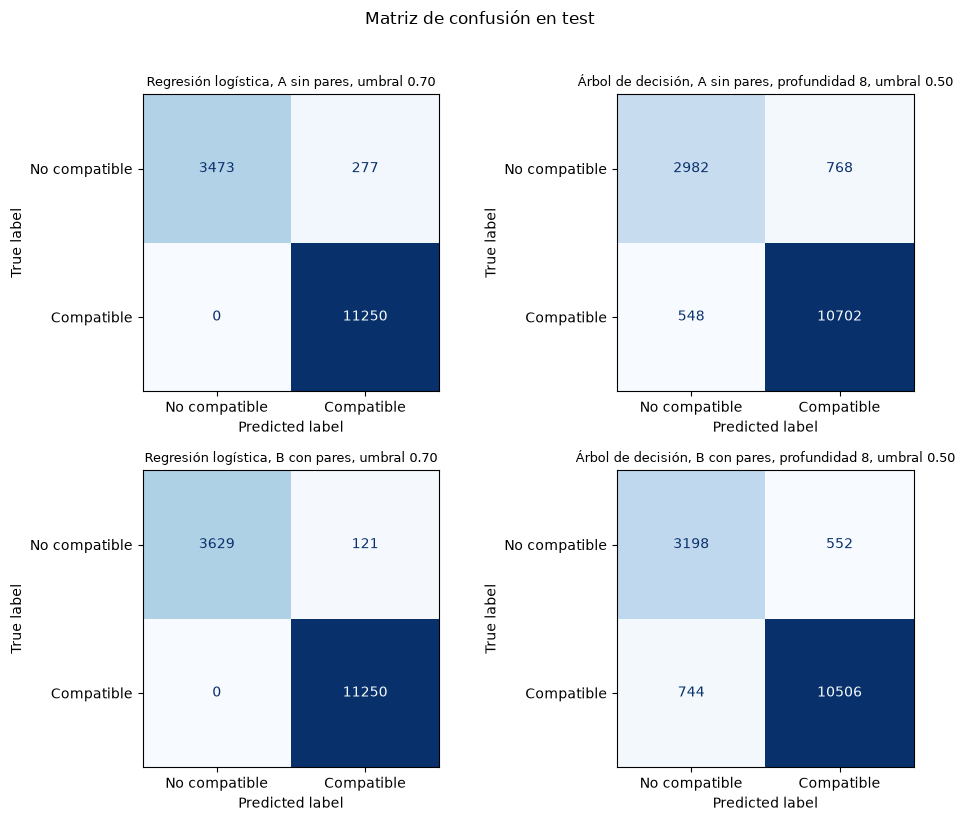

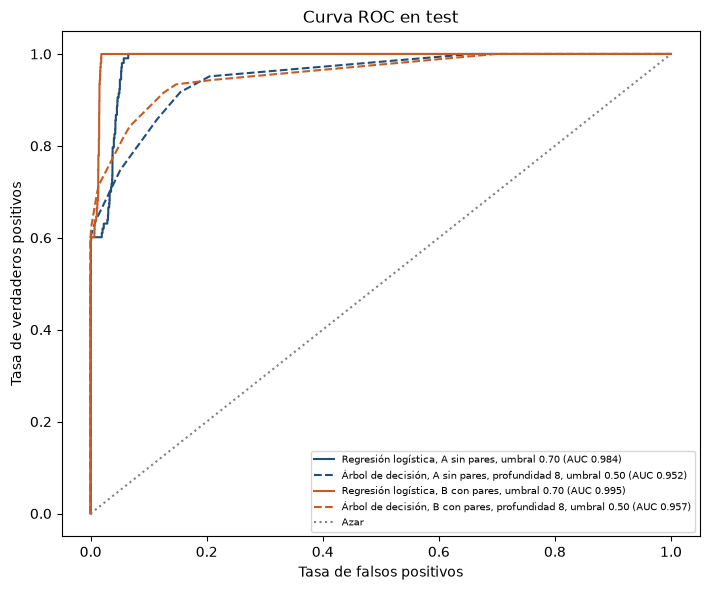

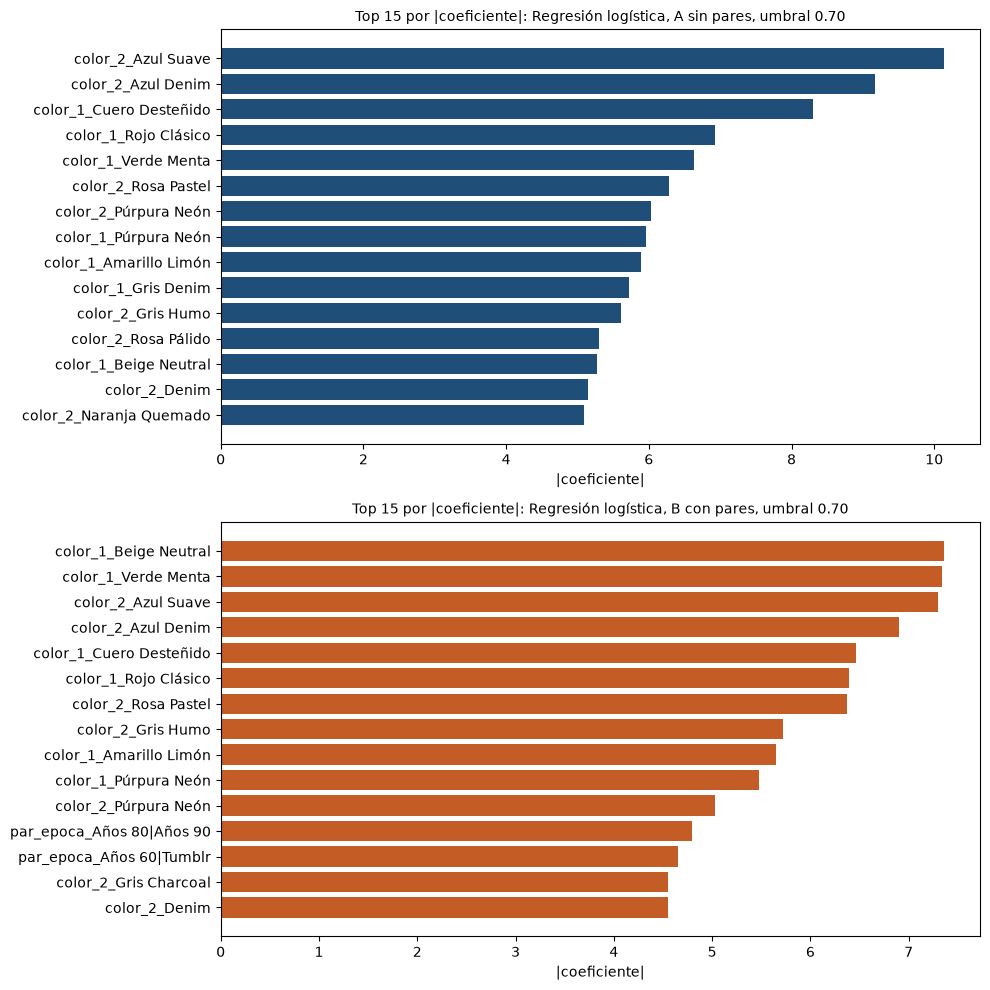

In [11]:
orden_plot = [("A", "logistica"), ("A", "arbol"), ("B", "logistica"), ("B", "arbol")]
fig, ejes = plt.subplots(2, 2, figsize=(10, 8))
for ax, clave in zip(ejes.ravel(), orden_plot):
    res = resultados_test[clave]
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        res["pred"],
        display_labels=["No compatible", "Compatible"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(etiqueta_modelo(res), fontsize=9)
fig.suptitle("Matriz de confusión en test", y=1.02)
fig.tight_layout()
fig.savefig(FIG / "matriz_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 6))
for clave, estilo in zip(orden_plot, ["-", "--", "-", "--"]):
    res = resultados_test[clave]
    fpr, tpr, _ = roc_curve(y_test, res["proba"])
    color = "#1f4e79" if clave[0] == "A" else "#c45c26"
    ax.plot(fpr, tpr, linestyle=estilo, color=color, label=f"{etiqueta_modelo(res)} (AUC {res['auc_roc']:.3f})")
ax.plot([0, 1], [0, 1], linestyle=":", color="0.5", label="Azar")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curva ROC en test")
ax.legend(loc="lower right", fontsize=7)
fig.tight_layout()
fig.savefig(FIG / "curva_roc.png", dpi=200, bbox_inches="tight")
plt.show()

def ganador_de(version):
    return max((fila for fila in finalistas if fila["version"] == version), key=puntaje_final)

fig, ejes = plt.subplots(2, 1, figsize=(10, 10))
for ax, version in zip(ejes, ["A", "B"]):
    fila = ganador_de(version)
    pipe = modelos_ajustados[(version, fila["modelo"], fila["profundidad"])]
    nombres = np.array([
        nombre.replace("cat__", "").replace("num__", "")
        for nombre in pipe.named_steps["prep"].get_feature_names_out()
    ])
    modelo = pipe.named_steps["model"]
    if hasattr(modelo, "feature_importances_"):
        valores = modelo.feature_importances_
        criterio = "impureza"
    else:
        valores = np.abs(modelo.coef_).ravel()
        criterio = "|coeficiente|"
    top = np.argsort(valores)[-15:]
    ax.barh(nombres[top], valores[top], color="#1f4e79" if version == "A" else "#c45c26")
    ax.set_title(f"Top 15 por {criterio}: {etiqueta_modelo(fila)}", fontsize=10)
    ax.set_xlabel(criterio)
fig.tight_layout()
fig.savefig(FIG / "importancia_top15.png", dpi=200, bbox_inches="tight")
plt.show()


## Los 30 casos

Se aplican las cuatro configuraciones cerradas en validación. No se reajustan.
El detalle de errores es el del modelo elegido e incluye los atributos y los cruces de par,
aunque la versión A no use esos cruces.


In [12]:
filas_30 = []
for fila in finalistas:
    feats = VERSIONES[fila["version"]][1]
    pipe = modelos_ajustados[(fila["version"], fila["modelo"], fila["profundidad"])]
    proba = pipe.predict_proba(casos[feats])[:, 1]
    pred = (proba >= fila["umbral"]).astype(int)
    y30 = casos["compatible"].to_numpy()
    filas_30.append({
        "version": fila["version"],
        "modelo": fila["modelo"],
        "accuracy": float(accuracy_score(y30, pred)),
        "f1": float(f1_score(y30, pred, pos_label=1, zero_division=0)),
        "n_errores": int((pred != y30).sum()),
    })
    if fila["version"] == elegido["version"] and fila["modelo"] == elegido["modelo"]:
        pred_elegido_30 = pred
        proba_elegido_30 = proba

tabla_30 = pd.DataFrame(filas_30)
print("Accuracy y F1 en los 30 casos:")
display(tabla_30.round(4))

mal = casos.loc[pred_elegido_30 != casos["compatible"].to_numpy()].copy()
mal["predicho"] = pred_elegido_30[pred_elegido_30 != casos["compatible"].to_numpy()]
mal["probabilidad"] = proba_elegido_30[pred_elegido_30 != casos["compatible"].to_numpy()]
columnas_error = [
    "test_id", "compatible", "predicho", "probabilidad", "n_prendas",
    "epoca_1", "epoca_2", "epoca_3", "par_epoca",
    "estilo_1", "estilo_2", "estilo_3", "par_estilo",
    "patron_1", "patron_2", "patron_3", "par_patron",
    "color_1", "color_2", "color_3",
    "misma_epoca", "mismo_estilo", "mismo_patron", "mismo_color",
    "razon",
]
mal = mal.sort_values("probabilidad", ascending=False)
print(f"Mal clasificados por el modelo elegido: {len(mal)} de {len(casos)}.")
if len(mal) == 0:
    print("Ningún caso de los 30 quedó mal clasificado.")
else:
    display(mal[columnas_error])


Accuracy y F1 en los 30 casos:


,version,modelo,accuracy,f1,n_errores
0,A,logistica,0.9667,0.9677,1
1,A,arbol,0.9667,0.9677,1
2,B,logistica,1.0000,1.0000,0
3,B,arbol,0.8667,0.8750,4


Mal clasificados por el modelo elegido: 0 de 30.
Ningún caso de los 30 quedó mal clasificado.


## Score continuo

Solo corre si el modelo elegido cumple los tres umbrales en test.
Se ajusta Ridge (`alpha` 1, sin búsqueda) sobre `score_compatibilidad`, con las mismas
features y las mismas filas de cada partición. Ridge, y no la regresión lineal sin penalizar,
porque el one-hot completo es colineal. El score no se usó como feature
de la clasificación.


Ridge A | validation: RMSE 0.1735, R² 0.6771
Ridge A | test: RMSE 0.1746, R² 0.6740


Ridge B | validation: RMSE 0.1538, R² 0.7465
Ridge B | test: RMSE 0.1552, R² 0.7422


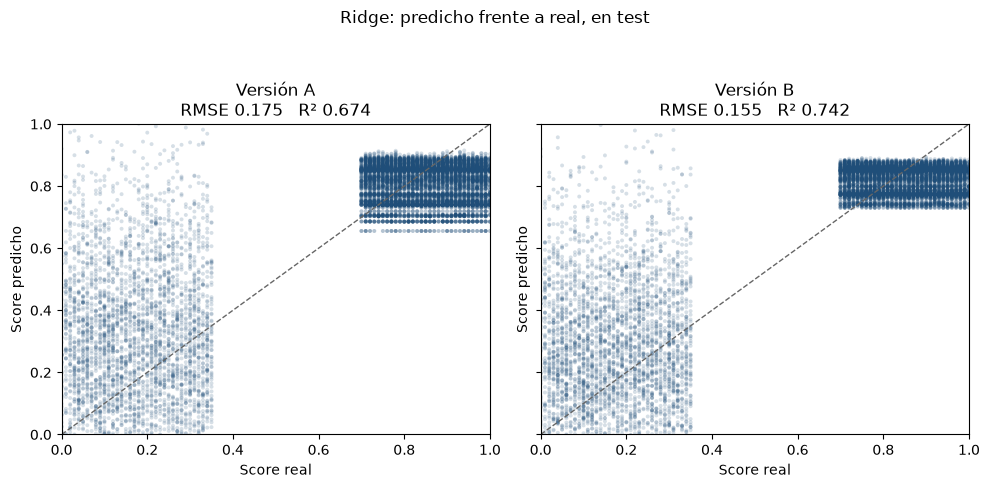

,version,conjunto,rmse,r2
0,A,validation,0.1735,0.6771
1,A,test,0.1746,0.6740
2,B,validation,0.1538,0.7465
3,B,test,0.1552,0.7422


In [13]:
regresion_hecha = elegido_test["cumple"] == "sí"
filas_regresion = []
if not regresion_hecha:
    print(
        "El modelo elegido no cumple los tres umbrales en test. "
        "No se ajusta el score continuo."
    )
else:
    score = df["score_compatibilidad"].to_numpy()
    fig, ejes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
    for ax, version in zip(ejes, ["A", "B"]):
        columnas_cat, feats = VERSIONES[version]
        pipe = hacer_pipeline(Ridge(alpha=1.0), columnas_cat)
        pipe.fit(df.iloc[idx_train][feats], score[idx_train])
        for conjunto, idx in [("validation", idx_val), ("test", idx_test)]:
            pred = pipe.predict(df.iloc[idx][feats])
            real = score[idx]
            fila = {
                "version": version,
                "conjunto": conjunto,
                "rmse": float(root_mean_squared_error(real, pred)),
                "r2": float(r2_score(real, pred)),
            }
            filas_regresion.append(fila)
            print(f"Ridge {version} | {conjunto}: RMSE {fila['rmse']:.4f}, R² {fila['r2']:.4f}")
        pred_test = pipe.predict(df.iloc[idx_test][feats])
        ax.scatter(score[idx_test], pred_test, s=8, alpha=0.18, c="#1f4e79", edgecolors="none")
        ax.plot([0, 1], [0, 1], linestyle="--", color="0.4", linewidth=1)
        test_fila = next(f for f in filas_regresion if f["version"] == version and f["conjunto"] == "test")
        ax.set_title(f"Versión {version}\nRMSE {test_fila['rmse']:.3f}   R² {test_fila['r2']:.3f}")
        ax.set_xlabel("Score real")
        ax.set_ylabel("Score predicho")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
    fig.suptitle("Ridge: predicho frente a real, en test", y=1.05)
    fig.tight_layout()
    fig.savefig(FIG / "scatter_score.png", dpi=200, bbox_inches="tight")
    plt.show()
    display(pd.DataFrame(filas_regresion).round(4))


## Guardado

Las figuras quedan en `figuras_baseline/` (PNG, 200 dpi) y las métricas en `metricas_baseline.csv`.


In [14]:
def agregar(fase, fila, extra=None):
    base = {col: np.nan for col in [
        "fase", "version", "modelo", "conjunto", "profundidad", "umbral_decision", "elegido",
        "accuracy", "f1", "precision", "recall", "auc_roc", "rmse", "r2",
        "cumple_accuracy", "cumple_f1", "cumple_auc", "cumple", "n_columnas",
    ]}
    base["fase"] = fase
    for clave, valor in fila.items():
        destino = "umbral_decision" if clave == "umbral" else clave
        if destino in base:
            base[destino] = valor
    if extra:
        base.update(extra)
    registro.append(base)

for nombre, metricas in referencia_trivial.items():
    agregar("referencia_trivial", metricas, {"version": "referencia", "modelo": "siempre_1", "conjunto": nombre})
agregar("referencia_trivial", trivial_test, {"conjunto": "test"})

for fila in filas_umbral_fijo:
    agregar("validacion_umbral_0.50", fila, {"conjunto": "validation"})
for fila in mejor_por_config.values():
    agregar("validacion_mejor_umbral", fila, {"conjunto": "validation"})
for fila in filas_test:
    agregar("test", fila, {"conjunto": "test"})
for fila in filas_30:
    agregar("casos_30", fila, {"conjunto": "test_30"})
for fila in filas_regresion:
    agregar("regresion_ridge", fila, {"modelo": "ridge"})
for version, ancho in ancho_onehot.items():
    agregar(
        "one_hot",
        {"version": version},
        {"conjunto": "train", "n_columnas": ancho["total"], "modelo": "encoder"},
    )

salida = pd.DataFrame(registro)
salida.to_csv(RES / "metricas_baseline.csv", index=False, encoding="utf-8-sig")
print("Métricas:", RES / "metricas_baseline.csv", "| filas", len(salida))
print("Figuras:", ", ".join(sorted(p.name for p in FIG.glob('*.png'))))

print("\n---")
print(f"Elegido en validación: {etiqueta_modelo(elegido)}.")
print(
    f"Test de ese modelo: accuracy {elegido_test['accuracy']:.4f} "
    f"(meta {UMBRAL_ACC:.2f}, {elegido_test['cumple_accuracy']}), "
    f"F1 {elegido_test['f1']:.4f} (meta {UMBRAL_F1:.2f}, {elegido_test['cumple_f1']}), "
    f"AUC-ROC {elegido_test['auc_roc']:.4f} (meta {UMBRAL_AUC:.2f}, {elegido_test['cumple_auc']})."
)
print(
    f"F1 de validación A {mejor_a['f1']:.4f} frente a B {mejor_b['f1']:.4f}. "
    f"En test, logística A {resultados_test[('A','logistica')]['f1']:.4f} / "
    f"B {resultados_test[('B','logistica')]['f1']:.4f}; "
    f"árbol A {resultados_test[('A','arbol')]['f1']:.4f} / "
    f"B {resultados_test[('B','arbol')]['f1']:.4f}."
)
print(
    f"Trivial siempre 1 en test: accuracy {trivial_test['accuracy']:.4f}, "
    f"F1 {trivial_test['f1']:.4f}. La base de compatible es 0.75, así que ese F1 ya supera 0.85."
)
print(
    f"Columnas tras el one-hot: A = {ancho_onehot['A']['total']} "
    f"({ancho_onehot['A']['atributos']} atributos + {ancho_onehot['A']['numericas']} numéricas), "
    f"B = {ancho_onehot['B']['total']} "
    f"({ancho_onehot['B']['atributos']} atributos + {ancho_onehot['B']['pares']} pares + "
    f"{ancho_onehot['B']['numericas']} numéricas)."
)
print(
    f"P(compatible | 3 prendas) = {tasa_compatible_tres:.4f}. "
    f"Score separado sin solape: {score_separa}. Color no entra al cruce de par."
)
print(
    f"Solape de los 30 con outfits_unido: {n_exacto} con el mismo orden de columnas "
    f"({n_exacto_train} en train); {n_conjunto} por conjunto de prendas "
    f"({n_conjunto_train} en train)."
)
if len(mal) == 0:
    print("Errores en los 30 casos, modelo elegido: ninguno.")
else:
    ids = ", ".join(mal["test_id"].astype(str))
    print(f"Errores en los 30 casos, modelo elegido ({len(mal)}): {ids}.")
if regresion_hecha:
    for fila in filas_regresion:
        print(f"Ridge {fila['version']} {fila['conjunto']}: RMSE {fila['rmse']:.4f}, R² {fila['r2']:.4f}.")
else:
    print("Regresión del score: no se ajustó.")


Métricas: C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\metricas_baseline.csv | filas 34
Figuras: curva_roc.png, importancia_top15.png, matriz_confusion.png, matriz_confusion_dos_prendas.png, scatter_score.png

---
Elegido en validación: Regresión logística, B con pares, umbral 0.70.
Test de ese modelo: accuracy 0.9919 (meta 0.82, sí), F1 0.9947 (meta 0.85, sí), AUC-ROC 0.9946 (meta 0.88, sí).
F1 de validación A 0.9883 frente a B 0.9954. En test, logística A 0.9878 / B 0.9947; árbol A 0.9421 / B 0.9419.
Trivial siempre 1 en test: accuracy 0.7500, F1 0.8571. La base de compatible es 0.75, así que ese F1 ya supera 0.85.
Columnas tras el one-hot: A = 288 (283 atributos + 5 numéricas), B = 396 (283 atributos + 108 pares + 5 numéricas).
P(compatible | 3 prendas) = 1.0000. Score separado sin solape: True. Color no entra al cruce de par.
Solape de los 30 con outfits_unido: 30 con el mismo orden de columnas (22 en train); 30 por conjunto de prendas (22 en train).
Errores en los 30

## Test solo con dos prendas

En el test se dejan únicamente los outfits con `n_prendas == 2`.
Ahí están todos los incompatibles: con tres prendas la etiqueta es siempre 1.
Se usan la logística A y la logística B ya ajustadas, con el umbral 0.70, y la referencia que predice siempre 1 en ese mismo subgrupo.


Test con n_prendas == 2: n=8236, compatible=1: 4486 (0.5447), compatible=0: 3750.
Métricas en test, solo n_prendas == 2:


,version,modelo,n,umbral,accuracy,f1,auc_roc,precision,recall,tn,fp,fn,tp
0,referencia,siempre_1,8236,NaN,0.5447,0.7052,0.5000,0.5447,1.0,0,3750,0,4486
1,A,logistica,8236,0.7,0.9664,0.9701,0.9596,0.9418,1.0,3473,277,0,4486
2,B,logistica,8236,0.7,0.9853,0.9867,0.9864,0.9737,1.0,3629,121,0,4486


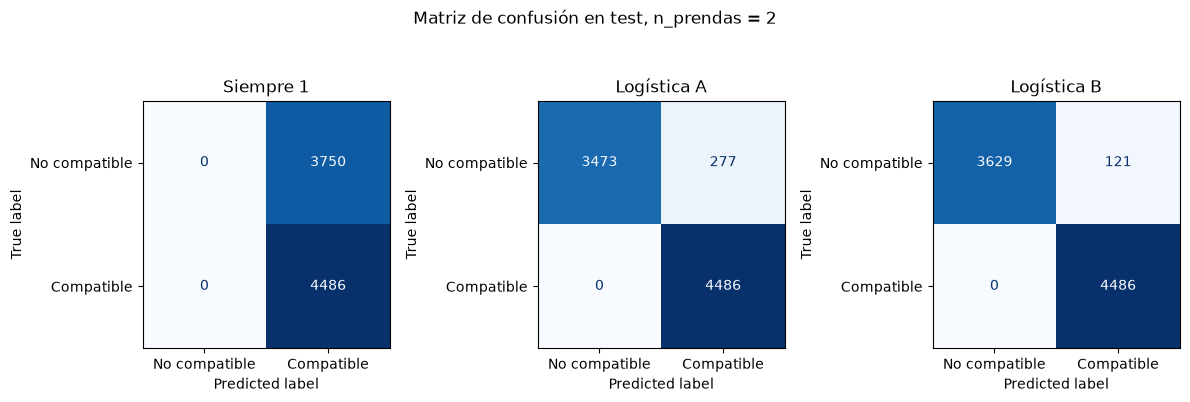

In [15]:
UMBRAL_FIJO = 0.70
mask_dos = df.iloc[idx_test]["n_prendas"].to_numpy() == 2
idx_test_dos = idx_test[mask_dos]
y_test_dos = y[idx_test_dos]
n_test_dos = int(len(y_test_dos))
print(
    f"Test con n_prendas == 2: n={n_test_dos}, "
    f"compatible=1: {int(y_test_dos.sum())} ({y_test_dos.mean():.4f}), "
    f"compatible=0: {int(n_test_dos - y_test_dos.sum())}."
)

from sklearn.metrics import confusion_matrix

pipes_logistica = {
    "A": modelos_ajustados[("A", "logistica", None)],
    "B": modelos_ajustados[("B", "logistica", None)],
}
filas_extra = []
predicciones_dos = {}

pred_trivial = np.ones(n_test_dos, dtype=int)
proba_trivial = np.ones(n_test_dos, dtype=float)
metricas_trivial = metricas_clasificacion(y_test_dos, pred_trivial, proba_trivial)
tn, fp, fn, tp = confusion_matrix(y_test_dos, pred_trivial, labels=[0, 1]).ravel()
filas_extra.append({
    "bloque": "test_dos_prendas",
    "grupo": "test_n_prendas_2",
    "version": "referencia",
    "modelo": "siempre_1",
    "n": n_test_dos,
    "umbral": None,
    **metricas_trivial,
    "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    "n_excluidas": None,
})
predicciones_dos[("referencia", "siempre_1")] = pred_trivial

for version, pipe in pipes_logistica.items():
    feats = VERSIONES[version][1]
    proba = pipe.predict_proba(df.iloc[idx_test_dos][feats])[:, 1]
    pred = (proba >= UMBRAL_FIJO).astype(int)
    metricas = metricas_clasificacion(y_test_dos, pred, proba)
    tn, fp, fn, tp = confusion_matrix(y_test_dos, pred, labels=[0, 1]).ravel()
    filas_extra.append({
        "bloque": "test_dos_prendas",
        "grupo": "test_n_prendas_2",
        "version": version,
        "modelo": "logistica",
        "n": n_test_dos,
        "umbral": UMBRAL_FIJO,
        **metricas,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "n_excluidas": None,
    })
    predicciones_dos[(version, "logistica")] = pred

tabla_dos = pd.DataFrame(filas_extra)
print("Métricas en test, solo n_prendas == 2:")
display(tabla_dos[[
    "version", "modelo", "n", "umbral", "accuracy", "f1", "auc_roc", "precision", "recall",
    "tn", "fp", "fn", "tp",
]].round(4))

fig, ejes = plt.subplots(1, 3, figsize=(12, 3.8))
paneles = [
    (("referencia", "siempre_1"), "Siempre 1"),
    (("A", "logistica"), "Logística A"),
    (("B", "logistica"), "Logística B"),
]
for ax, (clave, titulo) in zip(ejes, paneles):
    ConfusionMatrixDisplay.from_predictions(
        y_test_dos,
        predicciones_dos[clave],
        display_labels=["No compatible", "Compatible"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(titulo)
fig.suptitle("Matriz de confusión en test, n_prendas = 2", y=1.05)
fig.tight_layout()
fig.savefig(FIG / "matriz_confusion_dos_prendas.png", dpi=200, bbox_inches="tight")
plt.show()


## Los 30 casos, según si la combinación ya está en train

De los 30, 22 tienen la misma combinación de prendas en train. Aquí no se reajusta:
se aplican las logísticas A y B ya entrenadas, con umbral 0.70, por separado a ese grupo y al que no cae en train.
La combinación no depende del orden de las columnas.


In [16]:
en_train_30 = np.array([
    "train" in conjuntos[clave_conjunto(a, b, c)]
    for a, b, c in zip(casos["prenda_1"], casos["prenda_2"], casos["prenda_3"])
])
y_30 = casos["compatible"].to_numpy()
print(
    f"Casos con la combinación en train: {int(en_train_30.sum())}. "
    f"Casos fuera de train: {int((~en_train_30).sum())}."
)

filas_solape = []
for version, pipe in pipes_logistica.items():
    feats = VERSIONES[version][1]
    proba = pipe.predict_proba(casos[feats])[:, 1]
    pred = (proba >= UMBRAL_FIJO).astype(int)
    for grupo, mask in (("en_train", en_train_30), ("fuera_de_train", ~en_train_30)):
        filas_solape.append({
            "bloque": "casos_30_segun_train",
            "grupo": grupo,
            "version": version,
            "modelo": "logistica",
            "n": int(mask.sum()),
            "umbral": UMBRAL_FIJO,
            "accuracy": float(accuracy_score(y_30[mask], pred[mask])),
            "f1": float(f1_score(y_30[mask], pred[mask], pos_label=1, zero_division=0)),
            "precision": None,
            "recall": None,
            "auc_roc": None,
            "tn": None, "fp": None, "fn": None, "tp": None,
            "n_excluidas": None,
        })

tabla_solape = pd.DataFrame(filas_solape)
display(tabla_solape[["version", "grupo", "n", "accuracy", "f1"]].round(4))
filas_extra.extend(filas_solape)


Casos con la combinación en train: 22. Casos fuera de train: 8.


,version,grupo,n,accuracy,f1
0,A,en_train,22,0.9545,0.963
1,A,fuera_de_train,8,1.0000,1.000
2,B,en_train,22,1.0000,1.000
3,B,fuera_de_train,8,1.0000,1.000


## Reajuste sin esas combinaciones en train

Se excluyen del train todas las filas cuya combinación de prendas coincide con cualquiera de los 30.
Validación y test de la partición no se usan para este ajuste. La logística A y la B se vuelven a entrenar
con los mismos hiperparámetros (`liblinear`, `random_state` 42) y se evalúan en los 30 con umbral 0.70.


In [17]:
claves_30 = {
    clave_conjunto(a, b, c)
    for a, b, c in zip(casos["prenda_1"], casos["prenda_2"], casos["prenda_3"])
}
claves_df = [
    clave_conjunto(a, b, c)
    for a, b, c in zip(df["prenda_1"], df["prenda_2"], df["prenda_3"])
]
es_combo_30 = np.fromiter((clave in claves_30 for clave in claves_df), dtype=bool, count=len(claves_df))
n_excluidas = int(es_combo_30[idx_train].sum())
idx_train_limpio = idx_train[~es_combo_30[idx_train]]
print(f"Filas excluidas del train: {n_excluidas}.")
print(f"Train original: {len(idx_train)}. Train restante: {len(idx_train_limpio)}.")
print(f"Combinaciones distintas de los 30: {len(claves_30)}.")

filas_reajuste = []
for version in ("A", "B"):
    columnas_cat, feats = VERSIONES[version]
    pipe = hacer_pipeline(nueva_logistica(), columnas_cat)
    pipe.fit(df.iloc[idx_train_limpio][feats], y[idx_train_limpio])
    proba = pipe.predict_proba(casos[feats])[:, 1]
    pred = (proba >= UMBRAL_FIJO).astype(int)
    filas_reajuste.append({
        "bloque": "casos_30_reajuste",
        "grupo": "test_30",
        "version": version,
        "modelo": "logistica",
        "n": int(len(casos)),
        "umbral": UMBRAL_FIJO,
        "accuracy": float(accuracy_score(y_30, pred)),
        "f1": float(f1_score(y_30, pred, pos_label=1, zero_division=0)),
        "precision": float(precision_score(y_30, pred, pos_label=1, zero_division=0)),
        "recall": float(recall_score(y_30, pred, pos_label=1, zero_division=0)),
        "auc_roc": float(roc_auc_score(y_30, proba)),
        "tn": None, "fp": None, "fn": None, "tp": None,
        "n_excluidas": n_excluidas,
    })
    mal = casos.loc[pred != y_30, "test_id"]
    print(
        f"Logística {version} reajustada, en los 30: "
        f"accuracy {filas_reajuste[-1]['accuracy']:.4f}, F1 {filas_reajuste[-1]['f1']:.4f}. "
        f"Errores: {len(mal)}"
        + (f" ({', '.join(mal.astype(str))})." if len(mal) else ".")
    )

display(pd.DataFrame(filas_reajuste)[["version", "n", "n_excluidas", "accuracy", "f1"]].round(4))
filas_extra.extend(filas_reajuste)


Filas excluidas del train: 2985.
Train original: 70000. Train restante: 67015.
Combinaciones distintas de los 30: 29.


Logística A reajustada, en los 30: accuracy 0.7667, F1 0.7200. Errores: 7 (T004, T007, T008, T009, T012, T013, T026).


Logística B reajustada, en los 30: accuracy 0.8000, F1 0.7500. Errores: 6 (T004, T007, T008, T009, T012, T013).


,version,n,n_excluidas,accuracy,f1
0,A,30,2985,0.7667,0.72
1,B,30,2985,0.8000,0.75


## Guardado del complemento

Estas métricas van a `metricas_baseline_extra.csv`. `metricas_baseline.csv` no se modifica.


In [18]:
salida_extra = pd.DataFrame(filas_extra)
salida_extra.to_csv(RES / "metricas_baseline_extra.csv", index=False, encoding="utf-8-sig")
print("Guardado:", RES / "metricas_baseline_extra.csv", "| filas", len(salida_extra))
print(f"Filas excluidas del train al reajustar: {n_excluidas}.")


Guardado: C:\Users\Usuario\Documents\GitHub\modelo-fly\results\hito2\metricas_baseline_extra.csv | filas 9
Filas excluidas del train al reajustar: 2985.


In [19]:
import joblib
from sklearn.linear_model import Ridge

if "modelos_ajustados" not in globals():
    raise RuntimeError("Ejecuta el notebook completo en orden (Kernel → Restart & Run All): esta celda usa los modelos de la celda de entrenamiento.")

modelo_clf = modelos_ajustados[("B", "logistica", None)]
modelo_score = hacer_pipeline(Ridge(alpha=1.0), COLUMNAS_CAT_B)
modelo_score.fit(df.iloc[idx_train][FEATURES_B], df["score_compatibilidad"].to_numpy()[idx_train])

tr = df.iloc[idx_train]
combos_train = {clave_conjunto(a, b, c) for a, b, c in zip(tr["prenda_1"], tr["prenda_2"], tr["prenda_3"])}

MODELOS = ROOT / "models"
MODELOS.mkdir(exist_ok=True)
joblib.dump({"clf": modelo_clf, "score": modelo_score, "umbral": 0.70,
             "features": FEATURES_B, "combos_train": combos_train},
            MODELOS / "modelo_baseline.joblib")
print("Guardado:", MODELOS / "modelo_baseline.joblib", "| combinaciones en train:", len(combos_train))

Guardado: C:\Users\Usuario\Documents\GitHub\modelo-fly\models\modelo_baseline.joblib | combinaciones en train: 32491
